# Assignment 2: Principal Component Analysis (PCA)

## Objective
Apply Principal Component Analysis (PCA) to reduce the dimensionality of the Iris dataset from four features to two principal components.

## Tasks
- Load the Iris dataset.
- Standardize the features.
- Apply PCA to reduce the dataset to two dimensions.
- Visualize the transformed data.
- Calculate and interpret the explained variance ratio.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

print("Dataset shape:", X.shape)
print("\nFirst five rows:")
print(X.head())

Dataset shape: (150, 4)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized dataset shape:", X_scaled.shape)

Standardized dataset shape: (150, 4)


In [4]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("Reduced shape:", X_pca.shape)

print("\nFirst five transformed rows:")
print(X_pca[:5])

Original shape: (150, 4)
Reduced shape: (150, 2)

First five transformed rows:
[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]]


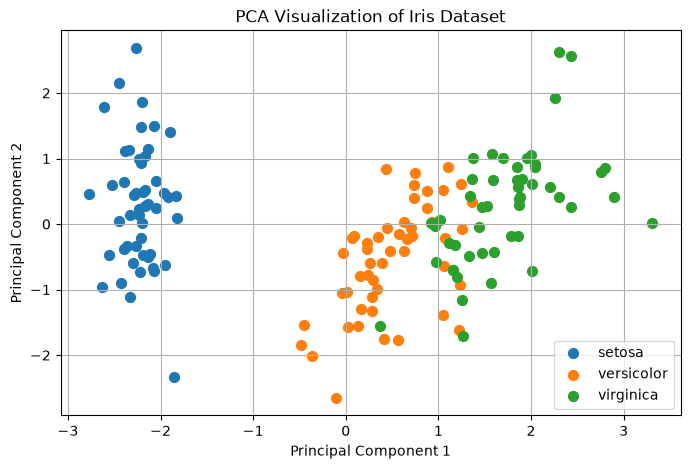

In [5]:
plt.figure(figsize=(8, 5))

for i, species in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=species,
        s=50
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio:")
print(explained_variance)

print("\nVariance explained by PC1:",
      round(explained_variance[0] * 100, 2), "%")

print("Variance explained by PC2:",
      round(explained_variance[1] * 100, 2), "%")

print("Total variance explained:",
      round(explained_variance.sum() * 100, 2), "%")

Explained variance ratio:
[0.72962445 0.22850762]

Variance explained by PC1: 72.96 %
Variance explained by PC2: 22.85 %
Total variance explained: 95.81 %


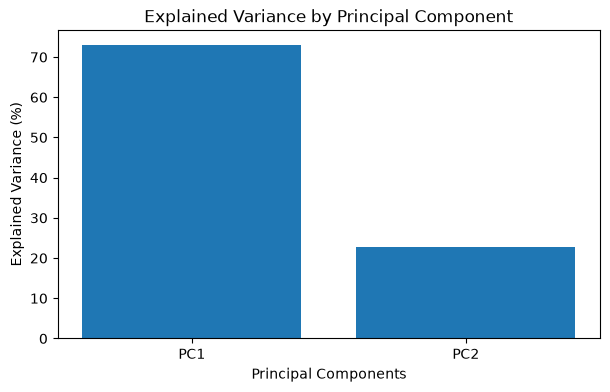

In [7]:
components = ["PC1", "PC2"]

plt.figure(figsize=(7, 4))
plt.bar(components, explained_variance * 100)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance by Principal Component")
plt.show()

## Conclusion

Principal Component Analysis (PCA) was applied to the Iris dataset to reduce its dimensionality from four features to two principal components. The features were standardized before PCA was performed. The transformed data was visualized using a scatter plot, and the explained variance ratio was calculated to evaluate the information retained by the two components. The first two principal components preserve approximately 95.81% of the total variance. This experiment demonstrates that PCA can simplify a dataset while retaining most of its important information, making visualization and further analysis easier.